# **Part 1: Data Wrangling and Preparation**

## **1. Import and Initial Exploration**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings
warnings.filterwarnings('ignore')

print('✅ Libraries imported successfully.')

gscore = pd.read_csv('genome_score.csv')
gtags = pd.read_csv('genome_tags.csv')
links = pd.read_csv('links.csv')
movies = pd.read_csv('movies.csv')
ratings = pd.read_csv('ratings.csv')
tags = pd.read_csv('tags.csv')

print('\n✅ Data imported successfully.')
print(f'genome_score dataset loaded: {gscore.shape[0]} rows x {gscore.shape[1]} columns')
print(f'genome_tags dataset loaded: {gtags.shape[0]} rows x {gtags.shape[1]} columns')
print(f'links dataset loaded: {links.shape[0]} rows x {links.shape[1]} columns')
print(f'movies dataset loaded: {movies.shape[0]} rows x {movies.shape[1]} columns')
print(f'ratings dataset loaded: {ratings.shape[0]} rows x {ratings.shape[1]} columns')
print(f'tags dataset loaded: {tags.shape[0]} rows x {tags.shape[1]} columns')

✅ Libraries imported successfully.

✅ Data imported successfully.
genome_score dataset loaded: 81216 rows x 3 columns
genome_tags dataset loaded: 1128 rows x 2 columns
links dataset loaded: 8305 rows x 3 columns
movies dataset loaded: 8305 rows x 3 columns
ratings dataset loaded: 192820 rows x 4 columns
tags dataset loaded: 470006 rows x 4 columns


### Data Orientation

In [ ]:
datasets = {
    'genome_score': gscore,
    'genome_tags': gtags,
    'links': links,
    'movies': movies,
    'ratings': ratings,
    'tags': tags
}

# First 10 rows
for name, df in datasets.items():
  print('=' * 65)
  print(name.upper(), 'FIRST 10 ROWS')
  print('=' * 65)
  print(df.head(10).to_string())
  print()

GENOME_SCORE FIRST 10 ROWS
   movieId  tagId  relevance
0     4253    269    0.12775
1     2209    101    0.03325
2     6179    905    0.02275
3     1501    420    0.05725
4     1798     19    0.23825
5     2525    733    0.14450
6     2296    207    0.01900
7     6577    323    0.14150
8      273    284    0.01675
9      543    512    0.30350

GENOME_TAGS FIRST 10 ROWS
   tagId           tag
0      1           007
1      2  007 (series)
2      3  18th century
3      4         1920s
4      5         1930s
5      6         1950s
6      7         1960s
7      8         1970s
8      9         1980s
9     10  19th century

LINKS FIRST 10 ROWS
   movieId  imdbId   tmdbId
0        1  114709    862.0
1        2  113497   8844.0
2        3  113228  15602.0
3        4  114885  31357.0
4        5  113041  11862.0
5        6  113277    949.0
6        7  114319  11860.0
7        8  112302  45325.0
8        9  114576   9091.0
9       10  113189    710.0

MOVIES FIRST 10 ROWS
   movieId             

In [ ]:
# Full struture
for name, df in datasets.items():
  print('=' * 65)
  print(name.upper(), 'FULL STRUCTURE')
  print('=' * 65)
  print(df.info())
  print()

GENOME_SCORE FULL STRUCTURE
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 81216 entries, 0 to 81215
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   movieId    81216 non-null  int64  
 1   tagId      81216 non-null  int64  
 2   relevance  80404 non-null  float64
dtypes: float64(1), int64(2)
memory usage: 1.9 MB
None

GENOME_TAGS FULL STRUCTURE
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1128 entries, 0 to 1127
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   tagId   1128 non-null   int64 
 1   tag     1128 non-null   object
dtypes: int64(1), object(1)
memory usage: 17.8+ KB
None

LINKS FULL STRUCTURE
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8305 entries, 0 to 8304
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   movieId  8305 non-null   int64  
 1   imdbId   8305 non-null   int

### Data Type and Type Correctness



In [ ]:
# INFERRED TYPE
for name, df in datasets.items():
  print('=' * 60)
  print(name.upper(), 'INFERRED DATA TYPES')
  print('=' * 60)
  print(df.dtypes.to_string())
  print()

# INSPECT
def inspect(df, col):
    print('=' * 60)
    print('INSPECT:', col, '(first 15 unique values)')
    print('=' * 60)
    print(df[col].unique()[:15])

inspect(ratings, 'timestamp')
print()

inspect(tags, 'timestamp')
print()

inspect(links, 'tmdbId')
print()

print('=' * 60)
print('TYPE MISMATCH FINDINGS')
print('=' * 60)
type_findings = [
    ('timestamp', 'object', 'date', 'HIGH', 'It was read from a CSV with mixed types or quoting issues'),
    ('tmdbId', 'float64', 'int64', 'MEDIUM', 'Some rows have missing values')
]
print(f'{"Column":<20} {"Current":<12} {"Expected":<14} {"Risk":<8} Note')
print('-' * 80)
for col, current, expected, risk, note in type_findings:
    print(f'{col:<20} {current:<12} {expected:<14} {risk:<8} {note}')

GENOME_SCORE INFERRED DATA TYPES
movieId        int64
tagId          int64
relevance    float64

GENOME_TAGS INFERRED DATA TYPES
tagId     int64
tag      object

LINKS INFERRED DATA TYPES
movieId      int64
imdbId       int64
tmdbId     float64

MOVIES INFERRED DATA TYPES
movieId     int64
title      object
genres     object

RATINGS INFERRED DATA TYPES
userId         int64
movieId        int64
rating       float64
timestamp     object

TAGS INFERRED DATA TYPES
userId        int64
movieId       int64
tag          object
timestamp    object

INSPECT: timestamp (first 15 unique values)
['2014-04-27 16:08:55' '1997-02-18 05:02:32' '2006-03-27 18:21:04'
 '2005-02-15 02:01:05' '2006-02-03 16:25:07' '2005-04-18 22:15:22'
 '2007-05-31 17:52:01' '2005-10-07 05:16:49' '2008-08-03 10:27:49'
 '2005-06-30 16:25:19' '2004-09-11 01:45:18' '2011-07-05 22:37:39'
 '2000-02-23 23:08:00' '2005-04-12 12:04:31' '1999-10-07 19:12:38']

INSPECT: timestamp (first 15 unique values)
['2015-08-13 13:25:55' '2015

### Missing Value Assessment

In [ ]:
# Count missing value per column
for name, df in datasets.items():
  print('=' * 60)
  print(name.upper(), 'MISSING VALUE COUNTS')
  print('=' * 60)
  print(df.isnull().sum().to_string())
  print()

# Missing as a PERCENTAGE of total rows
for name, df in datasets.items():
  print('=' * 60)
  print(name.upper(), 'MISSING VALUE PERCENTAGES WITH RISK LEVELS')
  print('=' * 60)
  missing_pct = (df.isnull().sum() / len(df) * 100).round(1)
  for col, pct in missing_pct.items():
      if pct > 0:
          risk = '🔴 HIGH' if pct > 20 else ('🟡 MODERATE' if pct > 5 else '🟢 LOW')
          print(f'  {col:<20} {pct:5.1f}%  {risk}')
      else:
          print(f'  {col:<20}   0.0%  complete')
  print()

# Total missing cells across all datasets
total_cells   = gscore.shape[0] * gscore.shape[1] + gtags.shape[0] * gtags.shape[1] + links.shape[0] * links.shape[1] + movies.shape[0] * movies.shape[1] + ratings.shape[0] * ratings.shape[1] + tags.shape[0] * tags.shape[1]
total_missing = gscore.isnull().sum().sum() + gtags.isnull().sum().sum() + links.isnull().sum().sum() + movies.isnull().sum().sum() + ratings.isnull().sum().sum() + tags.isnull().sum().sum()
print('=' * 60)
print('OVERALL MISSINGNESS SUMMARY')
print('=' * 60)
print(f'  Total cells in dataset  : {total_cells:,}')
print(f'  Total missing cells     : {total_missing:,}')
print(f'  Overall missingness rate: {total_missing/total_cells*100:.1f}%')
print()

# Check for ENCODED missingness in string columns
for name, df in datasets.items():
  print('=' * 60)
  print(name.upper(), 'ENCODED MISSINGNESS CHECK (string columns)')
  print('=' * 60)
  encoded_flags = ['n/a', 'na', 'none', 'unknown', 'missing', '-', '']
  for col in df.select_dtypes(include='object').columns:
      unique_vals = df[col].dropna().str.lower().unique()
      found = [v for v in unique_vals if v.strip() in encoded_flags]
      if found:
          print(f'  WARNING: {col}: encoded missing values -> {found}')
      else:
          print(f'  OK: {col}: no encoded missing values detected')
  print()


GENOME_SCORE MISSING VALUE COUNTS
movieId        0
tagId          0
relevance    812

GENOME_TAGS MISSING VALUE COUNTS
tagId    0
tag      0

LINKS MISSING VALUE COUNTS
movieId     0
imdbId      0
tmdbId     23

MOVIES MISSING VALUE COUNTS
movieId    0
title      0
genres     0

RATINGS MISSING VALUE COUNTS
userId          0
movieId         0
rating       5141
timestamp       0

TAGS MISSING VALUE COUNTS
userId        0
movieId       0
tag          11
timestamp     0

GENOME_SCORE MISSING VALUE PERCENTAGES WITH RISK LEVELS
  movieId                0.0%  complete
  tagId                  0.0%  complete
  relevance              1.0%  🟢 LOW

GENOME_TAGS MISSING VALUE PERCENTAGES WITH RISK LEVELS
  tagId                  0.0%  complete
  tag                    0.0%  complete

LINKS MISSING VALUE PERCENTAGES WITH RISK LEVELS
  movieId                0.0%  complete
  imdbId                 0.0%  complete
  tmdbId                 0.3%  🟢 LOW

MOVIES MISSING VALUE PERCENTAGES WITH RISK LEVELS


### Duplicate Record Assessment

In [ ]:
# Count exact duplicate rows
for name, df in datasets.items():
  exact_dups = df.duplicated().sum()
  print('=' * 60)
  print(name.upper(), 'EXACT DUPLICATE ROWS')
  print('=' * 60)
  print(f'  Duplicate rows: {exact_dups}')
  if exact_dups > 0:
    print(f'  Rows involved in duplication:')
    print(df[df.duplicated(keep=False)].to_string())
  print()

# Integrity check - movieId
movie_datasets = {
    'genome_score': gscore,
    'links': links,
    'movies': movies,
    'ratings': ratings,
    'tags': tags
}

for name, df in movie_datasets.items():
  print()
  print('=' * 60)
  print(f'{name.upper()} - MOVIE ID CHECK')
  print('=' * 60)

  total_rows = len(df)
  unique_ids = df['movieId'].nunique()
  duplicate_rows = df['movieId'].duplicated().sum()
  violation_rate = duplicate_rows / total_rows * 100

  print(f'Total rows: {total_rows}')
  print(f'Unique movieId values: {unique_ids}')
  print(f'Duplicate movieId rows: {duplicate_rows}')
  print(f'Violation rate: {violation_rate:.2f}%')

# Check for duplicate composite keys
def composite_key_check(df, df_name, key_cols):
    print()
    print('=' * 60)
    print(f'{df_name.upper()} - COMPOSITE KEY CHECK ({', '.join(key_cols)})')
    print('=' * 60)

    duplicate_composite_keys = df[df.duplicated(subset=key_cols, keep=False)]

    if not duplicate_composite_keys.empty:
        print(f'Found {len(duplicate_composite_keys)} rows with duplicate composite keys.')
        print('Examples of duplicate composite keys (first 10 rows):')
        print(duplicate_composite_keys.head(10).to_string())
    else:
        print('No duplicate composite keys found.')


# Apply composite key checks to relevant dataframes
composite_key_check(ratings, 'ratings', ['userId', 'movieId'])
composite_key_check(tags, 'tags', ['userId', 'movieId', 'tag'])
composite_key_check(gscore, 'genome_score', ['movieId', 'tagId'])

GENOME_SCORE EXACT DUPLICATE ROWS
  Duplicate rows: 0

GENOME_TAGS EXACT DUPLICATE ROWS
  Duplicate rows: 0

LINKS EXACT DUPLICATE ROWS
  Duplicate rows: 0

MOVIES EXACT DUPLICATE ROWS
  Duplicate rows: 0

RATINGS EXACT DUPLICATE ROWS
  Duplicate rows: 0

TAGS EXACT DUPLICATE ROWS
  Duplicate rows: 0


GENOME_SCORE - MOVIE ID CHECK
Total rows: 81216
Unique movieId values: 7200
Duplicate movieId rows: 74016
Violation rate: 91.13%

LINKS - MOVIE ID CHECK
Total rows: 8305
Unique movieId values: 8305
Duplicate movieId rows: 0
Violation rate: 0.00%

MOVIES - MOVIE ID CHECK
Total rows: 8305
Unique movieId values: 8305
Duplicate movieId rows: 0
Violation rate: 0.00%

RATINGS - MOVIE ID CHECK
Total rows: 192820
Unique movieId values: 8305
Duplicate movieId rows: 184515
Violation rate: 95.69%

TAGS - MOVIE ID CHECK
Total rows: 470006
Unique movieId values: 7938
Duplicate movieId rows: 462068
Violation rate: 98.31%

RATINGS - COMPOSITE KEY CHECK (userId, movieId)
No duplicate composite keys foun

### Categorical Consistency Check

In [ ]:
# Detect whitespace contamination
categorical_cols = {
    'genome_tags': ['tag'],
    'movies': ['genres', 'title'],
    'tags': ['tag']
}

for table_name, cols in categorical_cols.items():
    df = datasets[table_name]
    for col in cols:
        print('─' * 55)
        print(f' TABLE: {table_name}  COLUMN: {col}')
        print('─' * 55)
        raw_unique = df[col].nunique(dropna=True)
        normalized_unique = df[col].dropna().str.strip().str.lower().nunique()
        print(f'  Unique values (raw)        : {raw_unique}')
        print(f'  Unique values (normalized) : {normalized_unique}')
        print(f'  Possible case/space dupes  : {raw_unique - normalized_unique}')
        print(df[col].value_counts().head(10).to_string(header=False))
        print()

print('=' * 60)
print('WHITESPACE CONTAMINATION CHECK')
print('=' * 60)
for df_name, cols in categorical_cols.items():
    print(f'Checking DataFrame: {df_name}')
    df = datasets[df_name]
    for col in cols:
        if col in df.columns:
            # Ensure the column is of string type to apply .str.strip()
            df[col] = df[col].astype(str)
            has_ws = df[col].apply(
                lambda x: x != x.strip() if isinstance(x, str) else False
            ).sum()
            print(f'  {col}: {has_ws} values with leading/trailing whitespace')
        else:
            print(f'  Column {col} not found in {df_name}')

print()

# Flag low-frequency categories
threshold = 0.01 # Set threshold to 1%
print('=' * 60)
print(f'LOW-FREQUENCY VALUES (threshold = {threshold:.2%})')
print('=' * 60)
for df_name, cols_to_check in categorical_cols.items():
    print(f'Checking DataFrame: {df_name}')
    df_current = datasets[df_name] # Get the current dataframe
    for col in cols_to_check:
        if col in df_current.columns:
            value_counts = df_current[col].value_counts(normalize=True)
            low_freq_categories = value_counts[value_counts < threshold]

            if not low_freq_categories.empty:
                num_low_freq = len(low_freq_categories)
                print(f'  Column {col}: Found {num_low_freq} categories with frequency < {threshold:.2%}')
                if num_low_freq > 5: # Show only top 5 if too many
                    print(f'    Top 5 examples of low-frequency categories:')
                    for category, freq in low_freq_categories.head(5).items():
                        print(f'      - {category}: {freq:.2%}')
                    print(f'    ... and {num_low_freq - 5} more.')
                else:
                    print(f'    All low-frequency categories:')
                    for category, freq in low_freq_categories.items():
                        print(f'      - {category}: {freq:.2%}')
            else:
                print(f'  Column {col}: No low-frequency values found below {threshold:.2%}')
        else:
            print(f'  Column {col} not found in {df_name}')
print()

───────────────────────────────────────────────────────
 TABLE: genome_tags  COLUMN: tag
───────────────────────────────────────────────────────
  Unique values (raw)        : 1128
  Unique values (normalized) : 1128
  Possible case/space dupes  : 0
zombies         1
007             1
007 (series)    1
18th century    1
1920s           1
1930s           1
1950s           1
1960s           1
witch           1
wistful         1

───────────────────────────────────────────────────────
 TABLE: movies  COLUMN: genres
───────────────────────────────────────────────────────
  Unique values (raw)        : 664
  Unique values (normalized) : 664
  Possible case/space dupes  : 0
Drama                   1403
Comedy                   824
Comedy|Drama             402
Drama|Romance            352
Comedy|Romance           306
Documentary              245
Horror                   220
Comedy|Drama|Romance     202
Drama|Thriller           144
Crime|Drama              137

────────────────────────────────

### Numeric Distribution and Outlier Detection

In [ ]:
# Summary statistics
for name, df_current in datasets.items():
    print('=' * 60)
    print(f'SUMMARY STATISTICS FOR: {name.upper()}')
    print('=' * 60)
    # Exclude columns with 'id' in their name from numeric analysis
    numeric_cols = [col for col in df_current.select_dtypes(include=[np.number]).columns if 'id' not in col.lower()]
    if numeric_cols:
        print(df_current[numeric_cols].describe().round(2).to_string())
    else:
        print('No non-ID numeric columns found in this Dataset.')
    print()

# Check for negative relevance scores in genome_score
print('=' * 60)
print('GENOME_SCORE: ROWS WITH NEGATIVE RELEVANCE')
print('=' * 60)
negative_relevance = datasets['genome_score'][datasets['genome_score']['relevance'] < 0]
if not negative_relevance.empty:
    print(f'Found {len(negative_relevance)} rows with negative relevance values.')
    display(negative_relevance.head())
else:
    print('No negative relevance values found.')
print()
print('-' * 60)
print()

# Check for negative rating values in ratings
print('=' * 60)
print('RATINGS: ROWS WITH NEGATIVE RATINGS')
print('=' * 60)
negative_ratings = datasets['ratings'][datasets['ratings']['rating'] < 0]
if not negative_ratings.empty:
    print(f'Found {len(negative_ratings)} rows with negative rating values.')
    display(negative_ratings.head())
else:
    print('No negative rating values found.')
print()
print('-' * 60)
print()

# IQR-based outliers detection
for name, df_current in datasets.items():
    print('=' * 60)
    print(f'IQR-BASED OUTLIER DETECTION FOR: {name.upper()}')
    print('=' * 60)
    numeric_cols = [col for col in df_current.select_dtypes(include=[np.number]).columns if 'id' not in col.lower()]

    if not numeric_cols:
        print('No non-ID numeric columns found for outlier detection.')
        print('\n')
        continue

    for col in numeric_cols:
        Q1 = df_current[col].quantile(0.25)
        Q3 = df_current[col].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = df_current[(df_current[col] < lower_bound) | (df_current[col] > upper_bound)]

        if not outliers.empty:
            print(f'  Column \'{col}\' has {len(outliers)} outliers.')
            print(f'    Lower Bound: {lower_bound:.2f}, Upper Bound: {upper_bound:.2f}')
            print('    Examples of outliers (head of relevant column):')
            display(outliers[[col]].head())
        else:
            print(f'  Column \'{col}\' has no detected outliers.')
    print('\n')


SUMMARY STATISTICS FOR: GENOME_SCORE
       relevance
count   80404.00
mean        0.12
std         0.24
min        -0.98
25%         0.02
50%         0.06
75%         0.14
max         4.97

SUMMARY STATISTICS FOR: GENOME_TAGS
No non-ID numeric columns found in this Dataset.

SUMMARY STATISTICS FOR: LINKS
No non-ID numeric columns found in this Dataset.

SUMMARY STATISTICS FOR: MOVIES
No non-ID numeric columns found in this Dataset.

SUMMARY STATISTICS FOR: RATINGS
          rating
count  187679.00
mean        3.29
std         1.83
min        -5.00
25%         3.00
50%         3.50
75%         4.00
max        10.00

SUMMARY STATISTICS FOR: TAGS
No non-ID numeric columns found in this Dataset.

GENOME_SCORE: ROWS WITH NEGATIVE RELEVANCE
Found 541 rows with negative relevance values.


,movieId,tagId,relevance
48,6378,926,-0.16275
201,6398,644,-0.00550
691,4555,226,-0.02750
851,7221,399,-0.01400
867,4423,768,-0.64175



------------------------------------------------------------

RATINGS: ROWS WITH NEGATIVE RATINGS
Found 7712 rows with negative rating values.


,userId,movieId,rating,timestamp
0,118712,589,-5.0,2014-04-27 16:08:55
19,76250,6534,-2.5,2009-05-23 02:13:13
67,69288,1320,-3.5,2005-04-01 16:30:02
107,18477,1249,-4.0,2008-10-30 02:17:05
116,65710,1246,-3.5,2018-11-16 20:35:36



------------------------------------------------------------

IQR-BASED OUTLIER DETECTION FOR: GENOME_SCORE
  Column 'relevance' has 7655 outliers.
    Lower Bound: -0.15, Upper Bound: 0.31
    Examples of outliers (head of relevant column):


,relevance
48,-0.16275
61,0.39700
70,0.54100
73,0.46475
74,0.35400




IQR-BASED OUTLIER DETECTION FOR: GENOME_TAGS
No non-ID numeric columns found for outlier detection.


IQR-BASED OUTLIER DETECTION FOR: LINKS
No non-ID numeric columns found for outlier detection.


IQR-BASED OUTLIER DETECTION FOR: MOVIES
No non-ID numeric columns found for outlier detection.


IQR-BASED OUTLIER DETECTION FOR: RATINGS
  Column 'rating' has 18705 outliers.
    Lower Bound: 1.50, Upper Bound: 5.50
    Examples of outliers (head of relevant column):


,rating
0,-5.0
19,-2.5
20,0.5
49,0.5
67,-3.5




IQR-BASED OUTLIER DETECTION FOR: TAGS
No non-ID numeric columns found for outlier detection.




### Distribution Visualization for Numeric Values


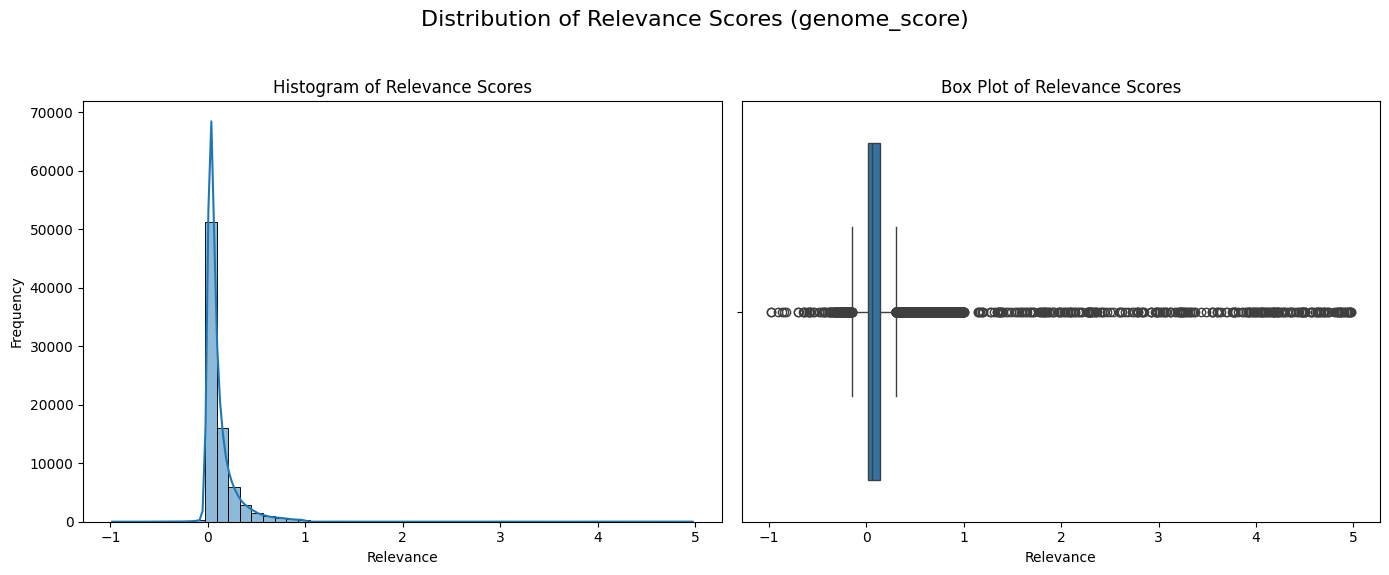

In [ ]:
# Visualize 'relevance' distribution in genome_score
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Distribution of Relevance Scores (genome_score)', fontsize=16)

# Histogram
sns.histplot(datasets['genome_score']['relevance'], bins=50, kde=True, ax=axes[0])
axes[0].set_title('Histogram of Relevance Scores')
axes[0].set_xlabel('Relevance')
axes[0].set_ylabel('Frequency')

# Box Plot
sns.boxplot(x=datasets['genome_score']['relevance'], ax=axes[1])
axes[1].set_title('Box Plot of Relevance Scores')
axes[1].set_xlabel('Relevance')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

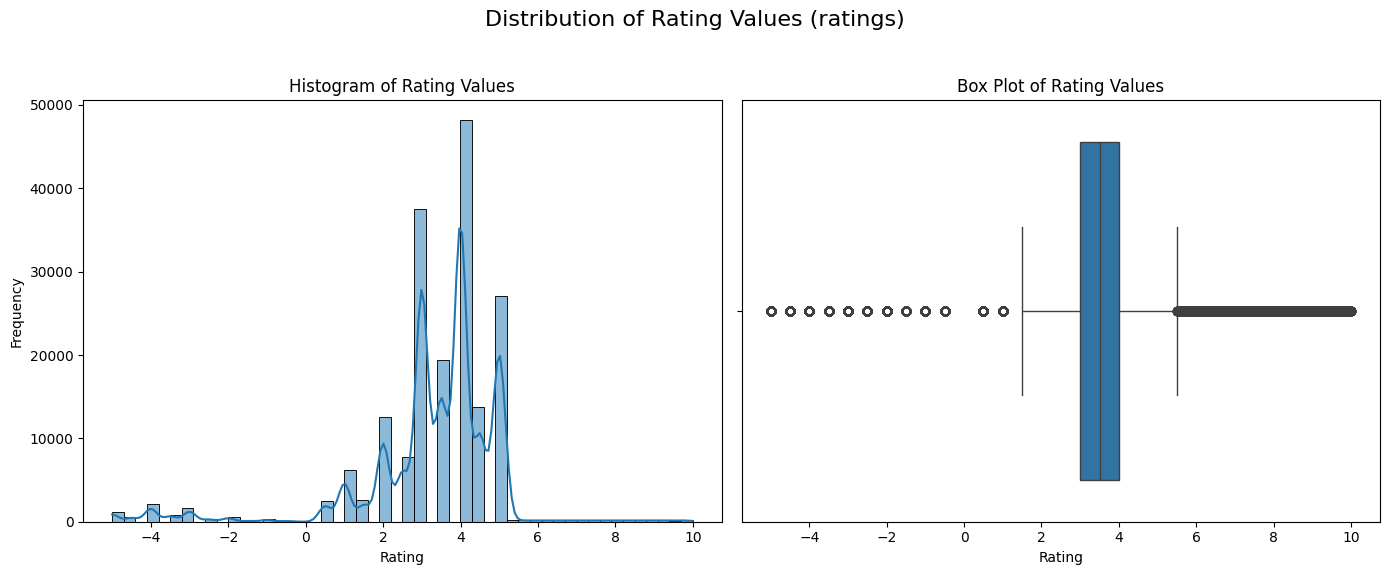

In [ ]:
# Visualize 'rating' distribution in ratings
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Distribution of Rating Values (ratings)', fontsize=16)

# Histogram
sns.histplot(datasets['ratings']['rating'].dropna(), bins=50, kde=True, ax=axes[0])
axes[0].set_title('Histogram of Rating Values')
axes[0].set_xlabel('Rating')
axes[0].set_ylabel('Frequency')

# Box Plot
sns.boxplot(x=datasets['ratings']['rating'].dropna(), ax=axes[1])
axes[1].set_title('Box Plot of Rating Values')
axes[1].set_xlabel('Rating')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

### Data Assessment Summary

In [ ]:
print('=' * 70)
print('  DATA ASSESSMENT SUMMARY')
print('  MovieLens Dataset Quality Assessment')
print('=' * 70)

print('\n📋 COMPONENT 1: DATASET OVERVIEW')
print('-' * 50)
print(f'  Source       : MovieLens dataset (Multiple CSV files)')
# Sum of rows across all dataframes
total_data_rows = sum(df_val.shape[0] for df_val in datasets.values())
print(f'  Total Records (across all datasets): {total_data_rows:,}')
print(f'  Representative Dataset (e.g., ratings):')
print(f'    Rows         : {datasets["ratings"].shape[0]:,}')
print(f'    Columns      : {datasets["ratings"].shape[1]}')
print(f'  Unit of analysis: Context dependent (e.g., one row = one rating, one tag, one movie info).')
print(f'  Time period  : Data spans from at least 1997-02-18 to 2019-11-16 (based on sample `timestamp` values in `ratings` and `tags`).')


# Component 2: Structure and Type Findings
print('\n🏷️  COMPONENT 2: STRUCTURE AND TYPE FINDINGS')
print('-' * 50)
type_issues = [
    ('ratings[\'timestamp\']', 'object', 'datetime64', 'HIGH', 'Read from CSV, should be datetime for time-series analysis.'),
    ('tags[\'timestamp\']', 'object', 'datetime64', 'HIGH', 'Read from CSV, should be datetime for time-series analysis.'),
    ('links[\'tmdbId\']', 'float64', 'int64', 'MEDIUM', 'Missing values (NaN) coerce column to float; logically should be int ID.')
]
print(f'  {"Column":<25} {"Current":<12} {"Needed":<13} {"Risk":<8} Note')
print(f'  {"- "*25} {"- "*12} {"- "*13} {"- "*8} {"- "*30}')
for col, current, needed, risk, note in type_issues:
    print(f'  {col:<25} {current:<12} {needed:<13} {risk:<8} {note}')

# Component 3: Quality Findings
print('\n🔍 COMPONENT 3: QUALITY FINDINGS')
print('-' * 50)

# Missingness
print('  [Missingness]')
print(f'    * `genome_score[\'relevance\']` : 1.0% missing (812 values) -- LOW risk')
print(f'    * `links[\'tmdbId\']`         : 0.3% missing (23 values) -- LOW risk')
print(f'    * `ratings[\'rating\']`        : 2.7% missing (5141 values) -- LOW risk')
print(f'    * `tags[\'tag\']`             : 0.0% missing (11 values) -- LOW risk')
print(f'    * Overall missingness rate: {total_missing/total_cells*100:.1f}% across all datasets.')
print(f'    * Encoded Missingness: `tags[\'tag\']` column contains encoded missing values such as \'\xa0\', \'missing\', \'na\'.')

# Duplicates
print('\n  [Duplicates]')
print(f'    * Exact duplicate rows: 0 (No exact duplicate rows found across any dataset).')
print(f'    * `movieId` Key Integrity:')
print(f'        * `links` and `movies` tables contain unique `movieId` values, serving as master lists.')
print(f'        * `genome_score`, `ratings`, `tags` tables show expected `movieId` duplication (e.g., `ratings`: {datasets["ratings"]["movieId"].duplicated().sum() / len(datasets["ratings"]) * 100:.2f}%) due to multiple interactions per movie. This is not a data quality issue for these tables.')
print(f'    * Composite Keys: No duplicate composite keys found for:')
print(f'        * `ratings`: (`userId`, `movieId`)')
print(f'        * `tags`: (`userId`, `movieId`, `tag`)')
print(f'        * `genome_score`: (`movieId`, `tagId`)')

# Categorical
print('\n  [Categorical Consistency]')
print(f'    * Whitespace Contamination: 81 values with leading/trailing whitespace detected in `tags[\'tag\']`.')
print(f'    * Low-Frequency Categories (threshold < 1.00%):')
print(f'        * `genome_tags[\'tag\']`: 1128 unique tags are low-frequency.')
print(f'        * `movies[\'genres\']`: 649 unique genre combinations are low-frequency.')
print(f'        * `movies[\'title\']`: 8305 unique titles are low-frequency (expected, as each title is unique).')
print(f'        * `tags[\'tag\']`: 37361 unique tags are low-frequency.')

# Outliers and Range Violations
print('\n  [Numeric Distribution and Outliers]')
print('    * Domain Knowledge Check (Impossible/Unusual Values):')
print(f'        * `genome_score[\'relevance\']`: 541 rows contain negative values (min -0.98), which is unusual for relevance scores.')
print(f'        * `ratings[\'rating\']`: 7,712 rows contain negative values (min -5.00), a significant domain violation as ratings are typically positive.')
print('    * IQR-Based Outlier Detection (excluding ID columns):')
print(f'        * `genome_score[\'relevance\']`: 7,655 outliers detected (Lower Bound: -0.15, Upper Bound: 0.31).')
print(f'        * `ratings[\'rating\']`: 18,705 outliers detected (Lower Bound: 1.50, Upper Bound: 5.50).')
print('    * Distribution Characteristics (from visualizations):')
print('        * `genome_score[\'relevance\']`: Heavily right-skewed distribution, peaking near zero, with many outliers (both negative and high positive).')
print('        * `ratings[\'rating\']`: Multi-modal distribution with peaks around common rating values (e.g., 3.0, 3.5, 4.0), and significant negative outliers and values outside the typical 1-5 range.')

# Component 4: Risk Rating
print('\n⚠️  COMPONENT 4: OVERALL RISK RATING')
print('-' * 50)
print('  Risk Level: HIGH')
print('  Justification:')
print('  (a) **Domain Violations**: Presence of negative `ratings[\'rating\']` and `genome_score[\'relevance\']` values represents a critical data quality issue.')
print('  (b) **Incorrect Data Types**: `timestamp` columns are `object` type, preventing direct time-series analysis and requiring conversion.')
print('  (c) **Categorical Inconsistencies**: Encoded missing values and whitespace in `tags[\'tag\']` require cleaning for accurate categorical analysis and matching.')
print('  (d) **Challenging Feature Engineering**: A large number of low-frequency categories across several features will complicate feature engineering for predictive models.')
print('  The dataset requires significant cleaning and transformation before reliable analysis or model building can proceed.')

# Component 5: Next Steps
print('\n✅ COMPONENT 5: RECOMMENDED NEXT STEPS')
print('-' * 50)
actions = [
    ('1', 'ratings[\'timestamp\'], tags[\'timestamp\']', 'Convert to `datetime64` objects for proper time-series analysis.'),
    ('2', 'ratings[\'rating\']', 'Address negative rating values; investigate source, set to `NaN`, or clip to 0 based on domain expert guidance.'),
    ('3', 'genome_score[\'relevance\']', 'Address negative relevance values; investigate source, set to `NaN`, or clip to 0 based on domain expert guidance.'),
    ('4', 'tags[\'tag\']', 'Clean whitespace using `.str.strip()` and handle encoded missing values (e.g., map to `NaN` or a specific "unknown" category).'),
    ('5', 'links[\'tmdbId\']', 'Handle missing values (e.g., impute or remove) and then convert to `int64`.'),
    ('6', 'Categorical features (low-frequency)', 'Develop strategies such as grouping rare categories, frequency encoding, or using one-hot encoding for top-N categories.'),
    ('7', 'Outliers in `relevance` and `rating`', 'Further investigate the nature and impact of detected outliers and decide on appropriate handling (e.g., winsorization, removal) based on analysis objectives.')
]
for num, col, action in actions:
    print(f'  {num}. [{col}] {action}')

print()
print('=' * 70)
print('  END OF DATA ASSESSMENT SUMMARY')
print('=' * 70)

  DATA ASSESSMENT SUMMARY
  MovieLens Dataset Quality Assessment

📋 COMPONENT 1: DATASET OVERVIEW
--------------------------------------------------
  Source       : MovieLens dataset (Multiple CSV files)
  Total Records (across all datasets): 761,780
  Representative Dataset (e.g., ratings):
    Rows         : 192,820
    Columns      : 4
  Unit of analysis: Context dependent (e.g., one row = one rating, one tag, one movie info).
  Time period  : Data spans from at least 1997-02-18 to 2019-11-16 (based on sample `timestamp` values in `ratings` and `tags`).

🏷️  COMPONENT 2: STRUCTURE AND TYPE FINDINGS
--------------------------------------------------
  Column                    Current      Needed        Risk     Note
  - - - - - - - - - - - - - - - - - - - - - - - - -  - - - - - - - - - - - -  - - - - - - - - - - - - -  - - - - - - - -  - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - 
  ratings['timestamp']      object       datetime64    HIGH     Read from CSV, should b

## **2. Cleaning Datasets**

### Removing Duplicate Records
Don't have to remove any duplicate records on genome_score, tags, and ratings because they contain composite key. In addition to that, later checks on duplicate records on composite key show no duplicate records.

### Handle Missing Value
These missing values in each dataset will be transfromed into NaN if needed

### Fix Categorical Inconsistent

In [ ]:
tags["tag"] = tags["tag"].str.strip().str.lower()
tags = tags[tags["tag"].notna() & (tags["tag"] != "")]

tags_raw_unique = tags['tag'].nunique(dropna=True)
tags_normalized_unique = tags['tag'].dropna().str.strip().str.lower().nunique()

print(f"Unique tags (raw)        : {tags_raw_unique}")
print(f"Unique tags (normalized) : {tags_normalized_unique}")
print(f"Case/whitespace dupes    : {tags_raw_unique - tags_normalized_unique}")

Unique tags (raw)        : 34009
Unique tags (normalized) : 34009
Case/whitespace dupes    : 0


### Convert Data Type

In [ ]:
# Convert timestampt's type to datetime64
ratings.loc[:, "timestamp"] = pd.to_datetime(ratings["timestamp"])
tags.loc[:, "timestamp"] = pd.to_datetime(tags["timestamp"])

# Convert [links['tmdbId']] to Int64 using convert_dtypes()
links.loc[:, "tmdbId"] = links["tmdbId"].convert_dtypes()

### Treat Outliers and Impossible Data Values

Impossible values

In [ ]:
# ratings['rating']
print('=' * 65)
print("ratings['rating']: valid range is 0.5-5.0 (MovieLens half-star scale)")
print('=' * 65)
print("BEFORE:")
print(f"  total rows        : {len(ratings):,}")
print(f"  nulls             : {ratings['rating'].isna().sum():,}")
print(f"  negative          : {(ratings['rating'] < 0).sum():,}")
print(f"  above 5.0         : {(ratings['rating'] > 5.0).sum():,}")

# Fix sign-flip corruption
is_negative = ratings['rating'] < 0
ratings.loc[is_negative, 'rating'] = ratings.loc[is_negative, 'rating'].abs()
print(f"\nFlipped {is_negative.sum():,} negative ratings back to positive")

# Drop nulls and remaining unrecoverable out-of-range values
ratings = ratings[ratings['rating'].notna()]
ratings = ratings[(ratings['rating'] >= 0.5) & (ratings['rating'] <= 5.0)]

print(f"AFTER: {len(ratings):,} rows remain")
print()

# gscore['relevance']
print('=' * 65)
print("genome_score['relevance']: valid range is 0.0-1.0 (it is a score)")
print('=' * 65)
print("BEFORE:")
print(f"  total rows        : {len(gscore):,}")
print(f"  nulls             : {gscore['relevance'].isna().sum():,}")
print(f"  negative          : {(gscore['relevance'] < 0).sum():,}")
print(f"  above 1.0         : {(gscore['relevance'] > 1.0).sum():,}")

# Fix sign-flip corruption
is_negative = gscore['relevance'] < 0
gscore.loc[is_negative, 'relevance'] = gscore.loc[is_negative, 'relevance'].abs()
print(f"\nFlipped {is_negative.sum():,} negative relevance scores back to positive")

# Drop nulls and remaining unrecoverable out-of-range values
genome_score = gscore[gscore['relevance'].notna()]
genome_score = genome_score[(genome_score['relevance'] >= 0.0) & (genome_score['relevance'] <= 1.0)]

print(f"AFTER: {len(genome_score):,} rows remain")

ratings['rating']: valid range is 0.5-5.0 (MovieLens half-star scale)
BEFORE:
  total rows        : 192,820
  nulls             : 5,141
  negative          : 7,712
  above 5.0         : 2,572

Flipped 7,712 negative ratings back to positive
AFTER: 185,107 rows remain

genome_score['relevance']: valid range is 0.0-1.0 (it is a score)
BEFORE:
  total rows        : 81,216
  nulls             : 812
  negative          : 541
  above 1.0         : 271

Flipped 541 negative relevance scores back to positive
AFTER: 80,133 rows remain


Outliers:
I don't have to worry about them because all the values in ratings['rating'] and gscore['relevance'] after flipped to postive are all in reasonable range.

### Before and After Comparison

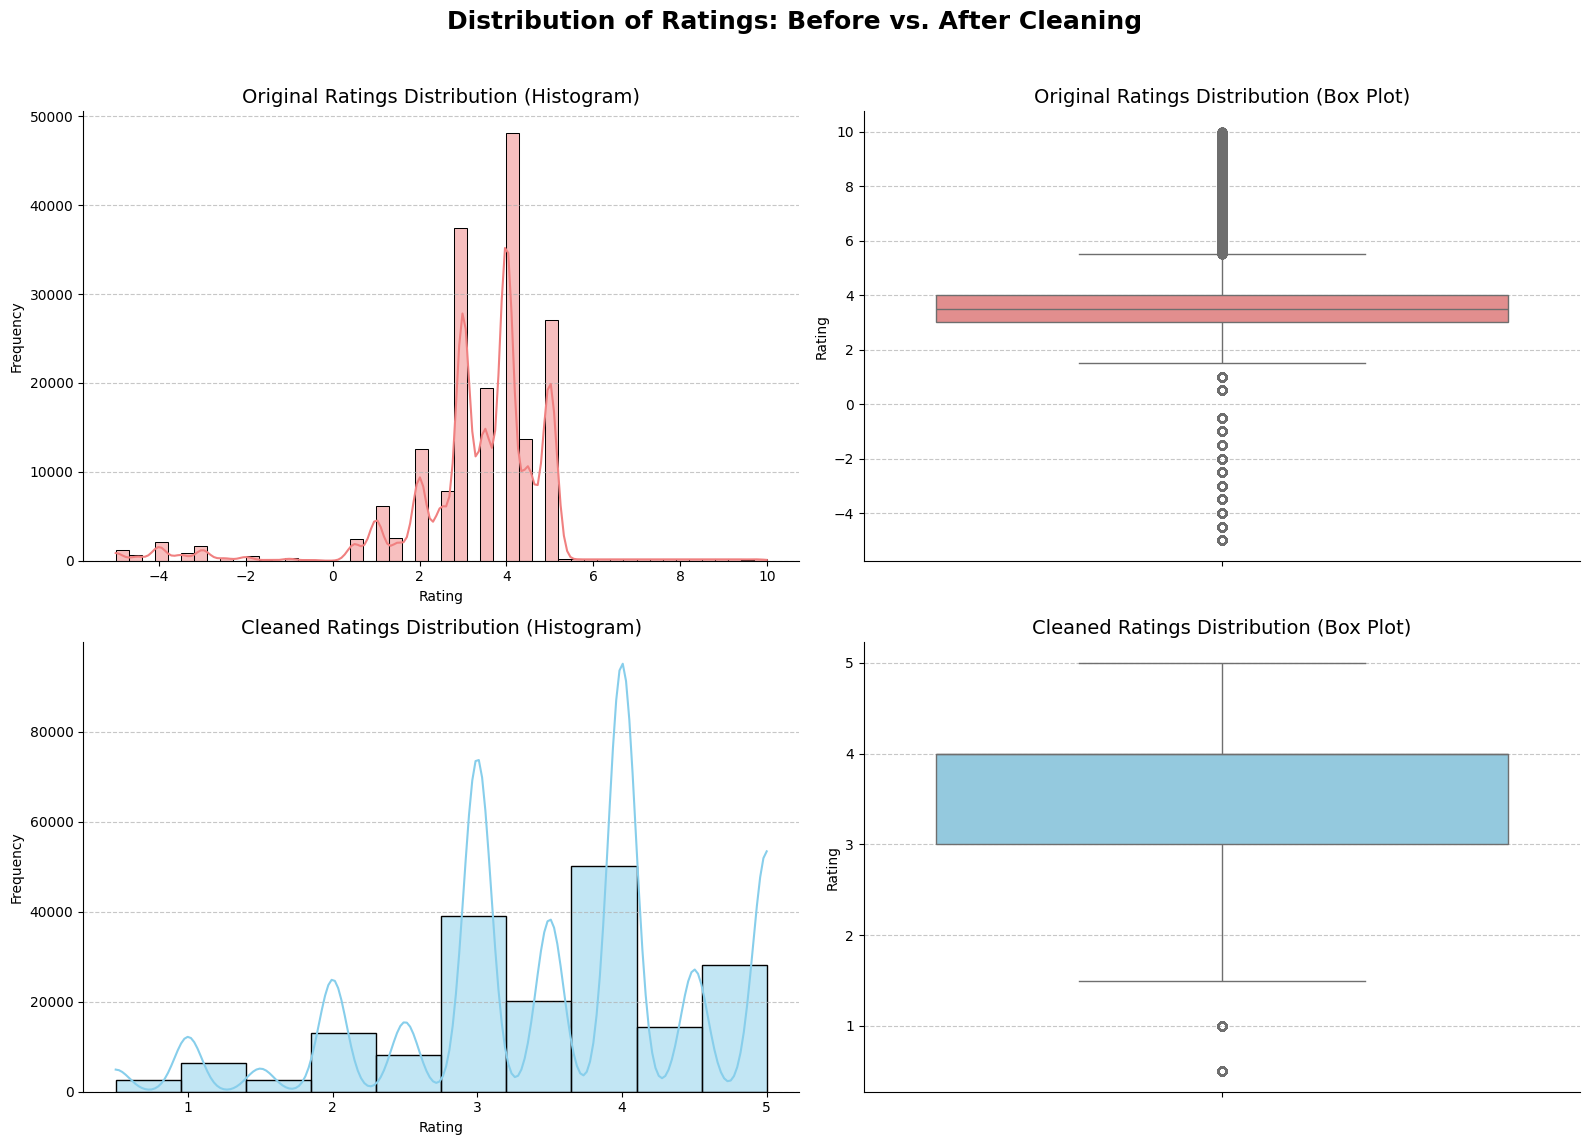

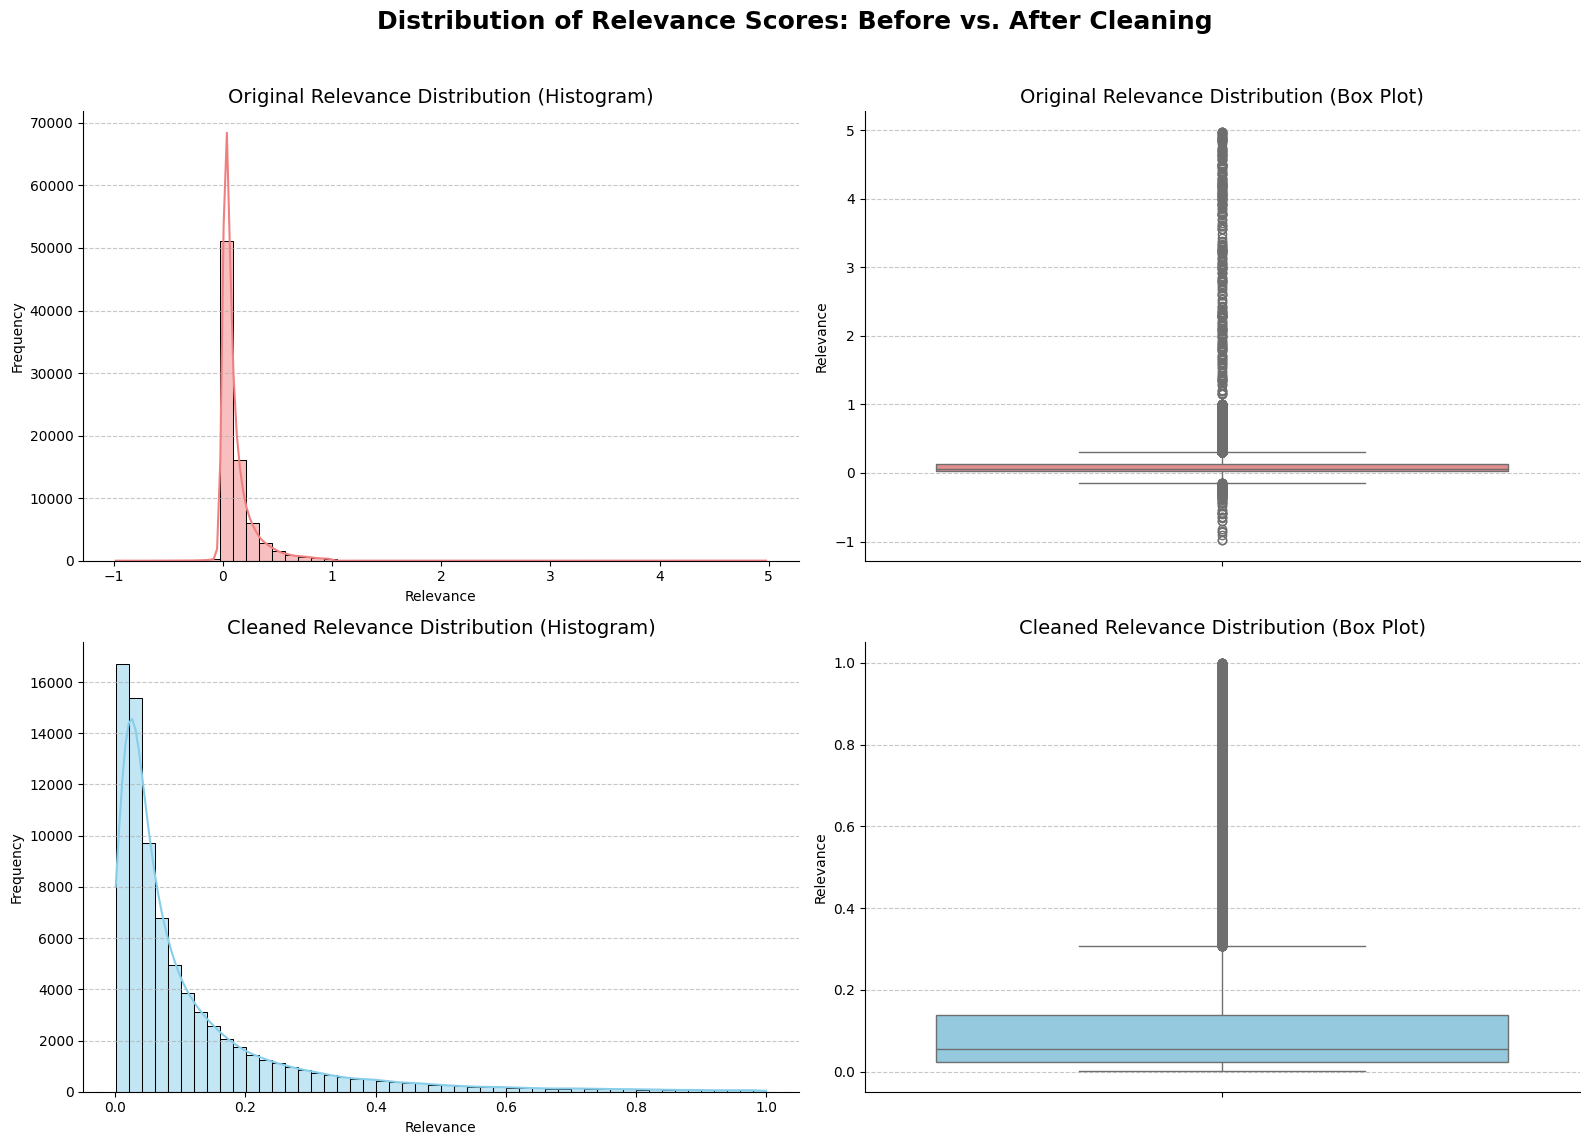

In [ ]:
# Reload original data for 'before' state from the /content/ directory
ratings_before = pd.read_csv('/content/ratings.csv')
gscore_before = pd.read_csv('/content/genome_score.csv')

# Create copies for 'after' state and apply cleaning operations
ratings_after = ratings_before.copy()
gscore_after_temp = gscore_before.copy()

# Apply cleaning for ratings_after
# Fix sign-flip corruption for ratings
is_negative_ratings = ratings_after['rating'] < 0
ratings_after.loc[is_negative_ratings, 'rating'] = ratings_after.loc[is_negative_ratings, 'rating'].abs()
# Drop nulls and remaining unrecoverable out-of-range values for ratings
ratings_after = ratings_after[ratings_after['rating'].notna()]
ratings_after = ratings_after[(ratings_after['rating'] >= 0.5) & (ratings_after['rating'] <= 5.0)]

# Apply cleaning for gscore_after
# Fix sign-flip corruption for relevance
is_negative_relevance = gscore_after_temp['relevance'] < 0
gscore_after_temp.loc[is_negative_relevance, 'relevance'] = gscore_after_temp.loc[is_negative_relevance, 'relevance'].abs()
# Drop nulls and remaining unrecoverable out-of-range values for relevance
gscore_after = gscore_after_temp[gscore_after_temp['relevance'].notna()]
gscore_after = gscore_after[(gscore_after['relevance'] >= 0.0) & (gscore_after['relevance'] <= 1.0)]

# --- Visualize Ratings Before and After Cleaning ---

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Distribution of Ratings: Before vs. After Cleaning', fontsize=18, fontweight='bold')

# Before Cleaning - Histogram
sns.histplot(ratings_before['rating'].dropna(), bins=50, kde=True, ax=axes[0, 0], color='lightcoral')
axes[0, 0].set_title('Original Ratings Distribution (Histogram)', fontsize=14)
axes[0, 0].set_xlabel('Rating')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].grid(axis='y', linestyle='--', alpha=0.7)

# Before Cleaning - Box Plot
sns.boxplot(y=ratings_before['rating'].dropna(), ax=axes[0, 1], color='lightcoral')
axes[0, 1].set_title('Original Ratings Distribution (Box Plot)', fontsize=14)
axes[0, 1].set_ylabel('Rating')
axes[0, 1].grid(axis='y', linestyle='--', alpha=0.7)

# After Cleaning - Histogram
sns.histplot(ratings_after['rating'].dropna(), bins=10, kde=True, ax=axes[1, 0], color='skyblue')
axes[1, 0].set_title('Cleaned Ratings Distribution (Histogram)', fontsize=14)
axes[1, 0].set_xlabel('Rating')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].grid(axis='y', linestyle='--', alpha=0.7)

# After Cleaning - Box Plot
sns.boxplot(y=ratings_after['rating'].dropna(), ax=axes[1, 1], color='skyblue')
axes[1, 1].set_title('Cleaned Ratings Distribution (Box Plot)', fontsize=14)
axes[1, 1].set_ylabel('Rating')
axes[1, 1].grid(axis='y', linestyle='--', alpha=0.7)

sns.despine(fig=fig) # Apply despine to the entire figure
plt.tight_layout(rect=[0, 0.03, 1, 0.96])
plt.show()

# --- Visualize Relevance Scores Before and After Cleaning ---

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Distribution of Relevance Scores: Before vs. After Cleaning', fontsize=18, fontweight='bold')

# Before Cleaning - Histogram
sns.histplot(gscore_before['relevance'].dropna(), bins=50, kde=True, ax=axes[0, 0], color='lightcoral')
axes[0, 0].set_title('Original Relevance Distribution (Histogram)', fontsize=14)
axes[0, 0].set_xlabel('Relevance')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].grid(axis='y', linestyle='--', alpha=0.7)

# Before Cleaning - Box Plot
sns.boxplot(y=gscore_before['relevance'].dropna(), ax=axes[0, 1], color='lightcoral')
axes[0, 1].set_title('Original Relevance Distribution (Box Plot)', fontsize=14)
axes[0, 1].set_ylabel('Relevance')
axes[0, 1].grid(axis='y', linestyle='--', alpha=0.7)

# After Cleaning - Histogram
sns.histplot(gscore_after['relevance'].dropna(), bins=50, kde=True, ax=axes[1, 0], color='skyblue')
axes[1, 0].set_title('Cleaned Relevance Distribution (Histogram)', fontsize=14)
axes[1, 0].set_xlabel('Relevance')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].grid(axis='y', linestyle='--', alpha=0.7)

# After Cleaning - Box Plot
sns.boxplot(y=gscore_after['relevance'].dropna(), ax=axes[1, 1], color='skyblue')
axes[1, 1].set_title('Cleaned Relevance Distribution (Box Plot)', fontsize=14)
axes[1, 1].set_ylabel('Relevance')
axes[1, 1].grid(axis='y', linestyle='--', alpha=0.7)

sns.despine(fig=fig) # Apply despine to the entire figure
plt.tight_layout(rect=[0, 0.03, 1, 0.96])
plt.show()

## **3. Merging DataFrame**

In [ ]:
# movies + links ->  one row per movieId (one-to-one)
# Key: movieId.
# This is a clean one-to-one join
movie_dim = movies.merge(links, on="movieId", how="left", validate="one_to_one")
print(f"movies + links merged on movieId (1:1) -> {len(movie_dim):,} rows")

# tags.csv  ->  summarised to one row per movieId
tag_summary = (
    tags.groupby("movieId")
    .agg(
        tag_count=("tag", "size"),                       # engagement volume
        unique_tag_count=("tag", "nunique"),              # vocabulary breadth
        top_tags=("tag", lambda s: "|".join(
            s.str.lower().value_counts().head(5).index)),  # 5 most-used tags
    )
    .reset_index()
)
print(f"\ntags aggregated: {len(tags):,} rows -> {len(tag_summary):,} rows "
      f"(one per movie that has at least one tag)")

# genome_score.csv + genome_tags.csv  ->  one row per movieId
# This is a clean many-to-one relationship on tagId (each row has exactly one tagId)
gscore_named = genome_score.merge(gtags, on="tagId", how="left", validate="many_to_one")

def top_genome_tags(group, n=5):
    top = group.sort_values("relevance", ascending=False).head(n)
    return "|".join(f"{t}:{r:.2f}" for t, r in zip(top["tag"], top["relevance"]))

genome_summary = (
    gscore_named.groupby("movieId")
    .apply(lambda g: pd.Series({
        "genome_top_tags": top_genome_tags(g),
        "genome_avg_relevance": g["relevance"].mean(),
    }), include_groups=False)
    .reset_index()
)
print(f"\ngenome_score aggregated: {len(genome_score):,} rows -> {len(genome_summary):,} "
      f"rows (one per movie with genome data)")

# Build the movie dimension: movie_dim + tag_summary + genome_summary
# All three are now at the same grain (one row per movieId), so these
# are safe one-to-one/left joins.
movie_dim = (
    movie_dim
    .merge(tag_summary, on="movieId", how="left", validate="one_to_one")
    .merge(genome_summary, on="movieId", how="left", validate="one_to_one")
)
print(f"\nFinal movie dimension table: {len(movie_dim):,} rows, "
      f"{movie_dim['movieId'].nunique():,} unique movieId")

# Attach the movie dimension to the ratings fact table
# Key: movieId. This is the many-to-one join the whole pipeline was
# built to protect: many ratings can point at the same movie, but each
# rating gets exactly one movie's metadata.
final = ratings.merge(movie_dim, on="movieId", how="left", validate="many_to_one")

assert len(final) == len(ratings), "Row count changed during final merge - investigate!"

print(f"\nFinal analysis-ready dataset: {len(final):,} rows, {final.shape[1]} columns")
print("Grain: one row per (userId, movieId) rating event, enriched with movie metadata.")

movies + links merged on movieId (1:1) -> 8,305 rows

tags aggregated: 470,001 rows -> 7,938 rows (one per movie that has at least one tag)

genome_score aggregated: 80,133 rows -> 7,200 rows (one per movie with genome data)

Final movie dimension table: 8,305 rows, 8,305 unique movieId

Final analysis-ready dataset: 185,107 rows, 13 columns
Grain: one row per (userId, movieId) rating event, enriched with movie metadata.


## **4. Final Dataset Validation**

In [ ]:
# Extract Release Year and Decade from Movie Titles in Part 1
final['release_year'] = final['title'].str.extract(r'\((\d{4})\)').astype(float)
final.dropna(subset=['release_year'], inplace=True)
final['release_year'] = final['release_year'].astype(int)
final['release_decade'] = (final['release_year'] // 10 * 10).astype(str) + 's'

# Ensure release_decade is an ordered categorical column
decades = sorted(final['release_decade'].unique())
final['release_decade'] = pd.Categorical(final['release_decade'], categories=decades, ordered=True)

# Extract genre diversity features in Part 1
final['genre_count'] = final['genres'].str.count(r'\|') + 1
final['genre_diversity'] = final['genre_count'].apply(lambda x: 'Single Genre' if x == 1 else 'Multiple Genres')

# Save the enriched analysis-ready final dataset
final.to_csv('movielens_analysis_ready.csv', index=False)
print('✅ Enriched dataset with release year, decade, and genre diversity features saved successfully.')

✅ Enriched dataset with release year, decade, and genre diversity features saved successfully.


In [ ]:
movielens = pd.read_csv('movielens_analysis_ready.csv', parse_dates=['timestamp'])

print("=" * 70)
print("1. SHAPE")
print("=" * 70)
print(f"Rows: {movielens.shape[0]:,}")
print(f"Columns: {movielens.shape[1]}")

print("\n" + "=" * 70)
print("2. VARIABLE NAMES AND TYPES")
print("=" * 70)
info = pd.DataFrame({
    "dtype": movielens.dtypes.astype(str),
    "non_null": movielens.notna().sum(),
    "null_count": movielens.isna().sum(),
    "null_pct": (movielens.isna().mean() * 100).round(2),
})
print(info.to_string())

print("\n" + "=" * 70)
print("3. DESCRIPTIVE STATISTICS - numeric columns")
print("=" * 70)
numeric_cols = ["rating", "tag_count", "unique_tag_count", "genome_avg_relevance", "release_year", "genre_count"]
print(movielens[numeric_cols].describe().round(3).to_string())

1. SHAPE
Rows: 185,107
Columns: 17

2. VARIABLE NAMES AND TYPES
                               dtype  non_null  null_count  null_pct
userId                         int64    185107           0      0.00
movieId                        int64    185107           0      0.00
rating                       float64    185107           0      0.00
timestamp             datetime64[ns]    185107           0      0.00
title                         object    185107           0      0.00
genres                        object    185107           0      0.00
imdbId                         int64    185107           0      0.00
tmdbId                       float64    185081          26      0.01
tag_count                    float64    184652         455      0.25
unique_tag_count             float64    184652         455      0.25
top_tags                      object    184652         455      0.25
genome_top_tags               object    184017        1090      0.59
genome_avg_relevance         float64   

# **Part 2: Exploration and Analysis**

## Question 1: Rating patterns by genre


Summary Table: Average Rating by Genre
                 mean  count       std
genre                                 
Film-Noir    3.984780   2004  0.860397
War          3.809257   9809  1.008003
Documentary  3.702186   1647  1.086388
Crime        3.689702  30743  1.018367
Mystery      3.683588  14203  1.001813
Drama        3.678215  80361  1.008235
Animation    3.611841  10582  1.030252
IMAX         3.575178   2381  1.036223
Western      3.574741   3860  1.054081
Musical      3.564956   8144  1.043988
Romance      3.548010  35305  1.049176
Fantasy      3.538239  19679  1.078966
Adventure    3.514577  41915  1.071245
Thriller     3.512310  48537  1.045329
Action       3.442494  51734  1.087558
Sci-Fi       3.432124  29296  1.101865
Comedy       3.420973  69495  1.088538
Children     3.413347  16093  1.098731
Horror       3.325551  14305  1.142785



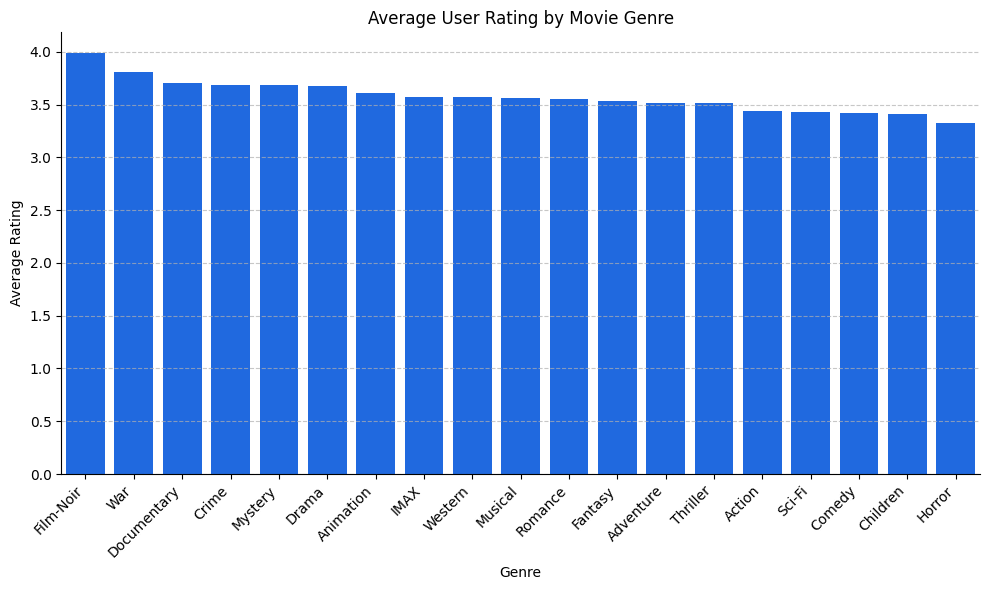

In [ ]:
movielens = pd.read_csv('movielens_analysis_ready.csv', parse_dates=['timestamp'])

# 1. Process genres: Explode the pipe-delimited genres into separate rows
genres_df = movielens.assign(genre=movielens['genres'].str.split('|')).explode('genre')

# Filter out movies with no listed genres (i.e., "(no genres listed)")
genres_df = genres_df[genres_df['genre'] != '(no genres listed)']

# 2. Calculate average rating for each genre
genre_ratings = genres_df.groupby('genre')['rating'].agg(['mean', 'count', 'std']).sort_values('mean', ascending=False)

# 3. Create a summary table
print("=" * 70)
print("Summary Table: Average Rating by Genre")
print("=" * 70)
print(genre_ratings.to_string())
print()

# 4. Visualize the average ratings per genre
plt.figure(figsize=(10, 6))
sns.barplot(x=genre_ratings.index, y=genre_ratings['mean'], color='#0062ff', legend=False)
plt.title('Average User Rating by Movie Genre')
plt.xlabel('Genre')
plt.ylabel('Average Rating')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)

sns.despine()
plt.tight_layout()
plt.show()

## Question 2: Tags, relevance, and movie engagement

Summary of Tagged vs. Untagged Movies
                 total_movies  mean_avg_rating  std_avg_rating  mean_num_ratings  std_num_ratings  total_tag_records
has_tags                                                                                                            
Untagged Movies           358             2.78            1.16              1.27             0.89                0.0
Tagged Movies            7836             3.19            0.85             23.56            58.32           468979.0



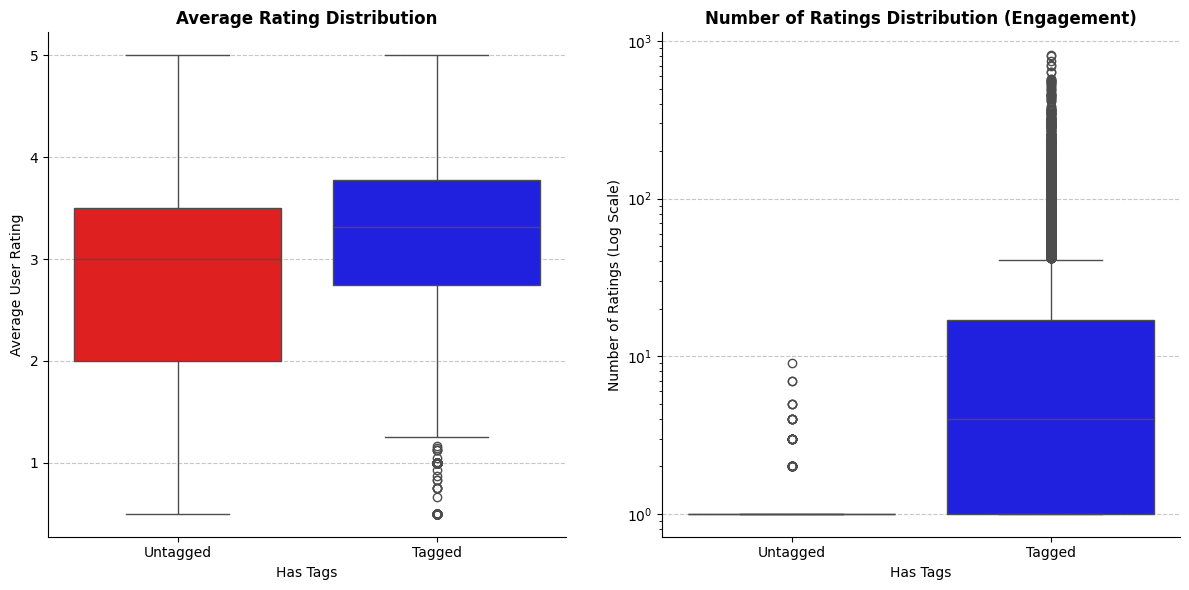

In [ ]:
# 1. Classify movies as tagged or untagged
# A movie is considered 'tagged' if it has a non-null 'tag_count' (which implies tag_count > 0 based on data cleaning).
# If 'tag_count' is NaN, it means no user tags were associated with that movie.

# Create a movie-level dataframe for analysis
# Group by movieId to get a single entry per movie, then aggregate relevant metrics.
movie_engagement_quality = movielens.groupby('movieId').agg(
    avg_rating=('rating', 'mean'),
    num_ratings=('rating', 'count'),
    has_tags=('tag_count', lambda x: x.iloc[0] > 0 if pd.notna(x.iloc[0]) else False),
    total_tag_count=('tag_count', 'first') # Get the total count of tags for the movie
).reset_index()

# 2. Summary statistics for tagged vs. untagged movies
print("=" * 70)
print("Summary of Tagged vs. Untagged Movies")
print("=" * 70)
summary_stats = movie_engagement_quality.groupby('has_tags').agg(
    total_movies=('movieId', 'count'),
    mean_avg_rating=('avg_rating', 'mean'),
    std_avg_rating=('avg_rating', 'std'),
    mean_num_ratings=('num_ratings', 'mean'),
    std_num_ratings=('num_ratings', 'std'),
    total_tag_records=('total_tag_count', 'sum') # Sum of tag counts
)
summary_stats.index = summary_stats.index.map({True: 'Tagged Movies', False: 'Untagged Movies'})
print(summary_stats.round(2).to_string())
print()

# 3. Visualizations
plt.figure(figsize=(12, 6))

# Define custom palette for tagged vs untagged
# Use string keys 'True' and 'False' to match how seaborn processes boolean columns
custom_tag_palette_str = {'True': 'blue', 'False': 'red'}

# Distribution of Average Ratings
plt.subplot(1, 2, 1)
sns.boxplot(x='has_tags', y='avg_rating', data=movie_engagement_quality, palette=custom_tag_palette_str)
plt.title('Average Rating Distribution', fontweight='bold')
plt.xlabel('Has Tags')
plt.ylabel('Average User Rating')
plt.xticks([0, 1], ['Untagged', 'Tagged'])
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Distribution of Number of Ratings (Engagement)
plt.subplot(1, 2, 2)
sns.boxplot(x='has_tags', y='num_ratings', data=movie_engagement_quality, palette=custom_tag_palette_str)
plt.title('Number of Ratings Distribution (Engagement)', fontweight='bold')
plt.xlabel('Has Tags')
plt.ylabel('Number of Ratings (Log Scale)')
plt.xticks([0, 1], ['Untagged', 'Tagged'])
plt.yscale('log') # Use log scale for better visualization due to large range
plt.grid(axis='y', linestyle='--', alpha=0.7)

sns.despine()
plt.tight_layout(w_pad=3.0)
plt.show()

## Question 3: Release year and audience response

Summary Table: Movie-Level Metrics by Release Year (First 10 Years)
   release_year  avg_rating  total_movies  total_tag_count
0          1914    2.500000             1              2.0
1          1915    2.333333             1             35.0
2          1916    3.833333             1             24.0
3          1917    4.000000             1             26.0
4          1918    3.750000             1             23.0
5          1919    2.500000             4             63.0
6          1920    4.122807             3            162.0
7          1921    3.714286             2             85.0
8          1922    2.754839             5            157.0
9          1923    3.137500             4             65.0

Summary Table: Movie-Level Metrics by Release Decade
  release_decade  avg_rating  total_movies  total_tag_count
0          1910s    2.935185             9            173.0
1          1920s    3.348533            53           1686.0
2          1930s    3.575632           160       

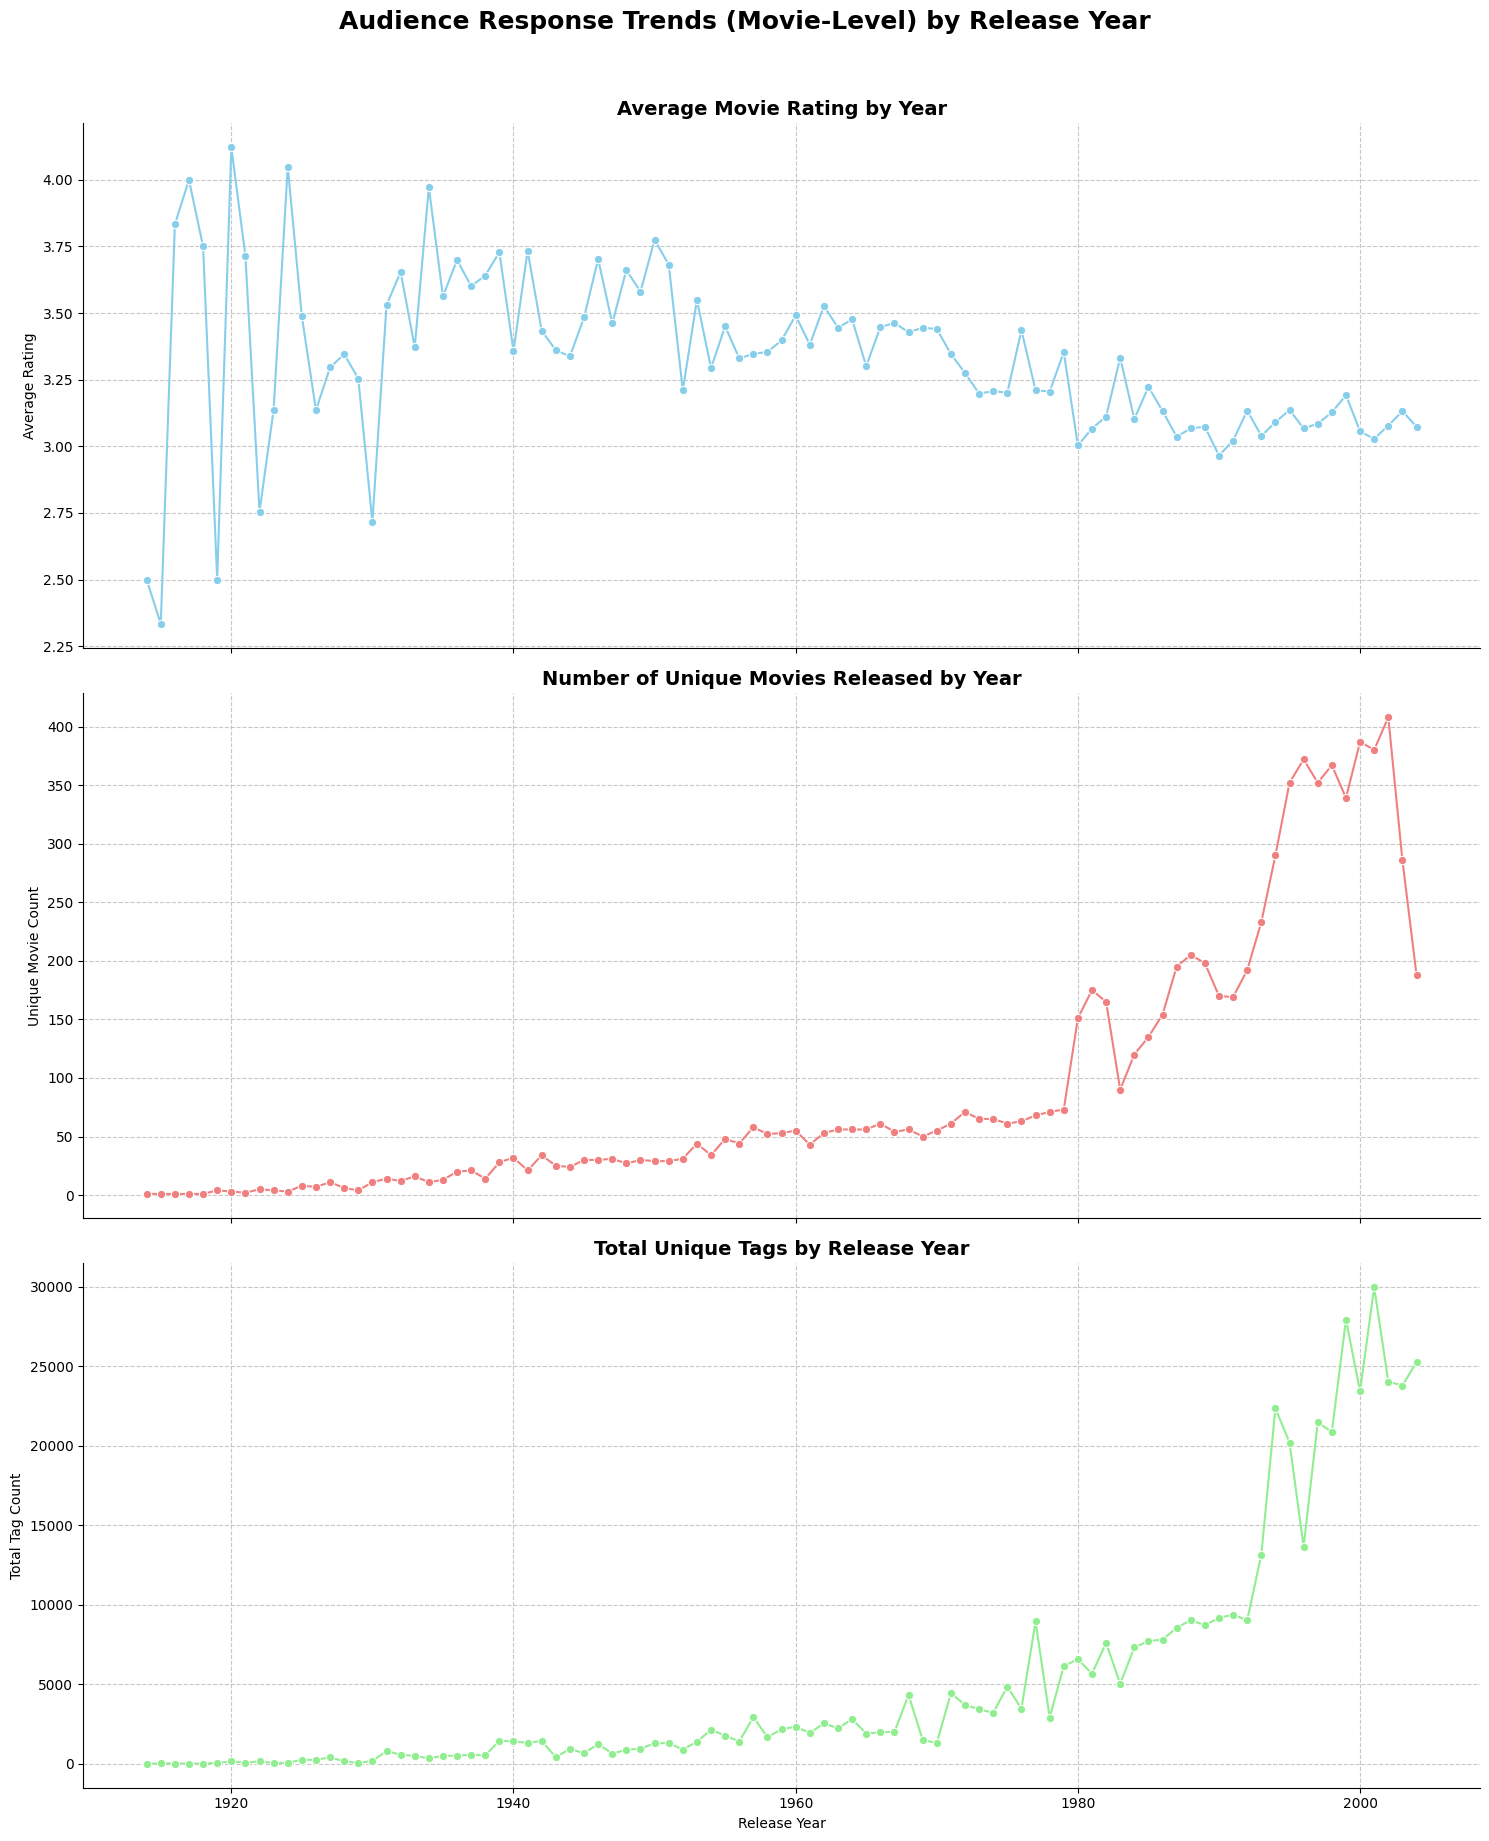

In [ ]:
# 1. Aggregate to the movie level first to avoid grain inflation (one row per movieId)
movie_level = movielens.groupby('movieId').agg({
    'release_year': 'first',
    'release_decade': 'first',
    'rating': 'mean', # average rating for this movie
    'tag_count': 'first' # unique tag count for this movie
}).reset_index()

# Fill NaN values in tag_count with 0 at the movie level
movie_level['tag_count'] = movie_level['tag_count'].fillna(0)

# 2. Group by Release Year
yearly_metrics = movie_level.groupby('release_year').agg(
    avg_rating=('rating', 'mean'),           # Average of movie averages
    total_movies=('movieId', 'count'),       # Total unique movies released
    total_tag_count=('tag_count', 'sum')     # True unique tag counts associated with these movies
).reset_index()

# 3. Group by Release Decade
decade_metrics = movie_level.groupby('release_decade', observed=False).agg(
    avg_rating=('rating', 'mean'),
    total_movies=('movieId', 'count'),
    total_tag_count=('tag_count', 'sum')
).reset_index()

print("=" * 75)
print("Summary Table: Movie-Level Metrics by Release Year (First 10 Years)")
print("=" * 75)
print(yearly_metrics.head(10).to_string())
print()

print("=" * 75)
print("Summary Table: Movie-Level Metrics by Release Decade")
print("=" * 75)
print(decade_metrics.to_string())

# 4. Visualizations
fig, axes = plt.subplots(3, 1, figsize=(15, 18), sharex=True)
fig.suptitle('Audience Response Trends (Movie-Level) by Release Year', fontsize=18, y=1.02, fontweight='bold')

sns.lineplot(x='release_year', y='avg_rating', data=yearly_metrics, ax=axes[0], marker='o', color='skyblue')
axes[0].set_title('Average Movie Rating by Year', fontweight='bold', fontsize=14)
axes[0].set_ylabel('Average Rating')
axes[0].grid(True, linestyle='--', alpha=0.7)
sns.despine(ax=axes[0])

sns.lineplot(x='release_year', y='total_movies', data=yearly_metrics, ax=axes[1], marker='o', color='lightcoral')
axes[1].set_title('Number of Unique Movies Released by Year', fontweight='bold', fontsize=14)
axes[1].set_ylabel('Unique Movie Count')
axes[1].grid(True, linestyle='--', alpha=0.7)
sns.despine(ax=axes[1])

sns.lineplot(x='release_year', y='total_tag_count', data=yearly_metrics, ax=axes[2], marker='o', color='lightgreen')
axes[2].set_title('Total Unique Tags by Release Year', fontweight='bold', fontsize=14)
axes[2].set_ylabel('Total Tag Count')
axes[2].set_xlabel('Release Year')
axes[2].grid(True, linestyle='--', alpha=0.7)
sns.despine(ax=axes[2])

plt.tight_layout()
plt.show()

## Question 4: Genre combinations and engagement patterns

Summary Table: Movie-Level Audience Response by Genre Diversity
   genre_diversity  avg_rating  avg_ratings_per_movie  avg_tags_per_movie  total_movies
0  Multiple Genres    3.191750              29.967140           75.678398          5143
1     Single Genre    3.136963              10.156014           26.143887          3051



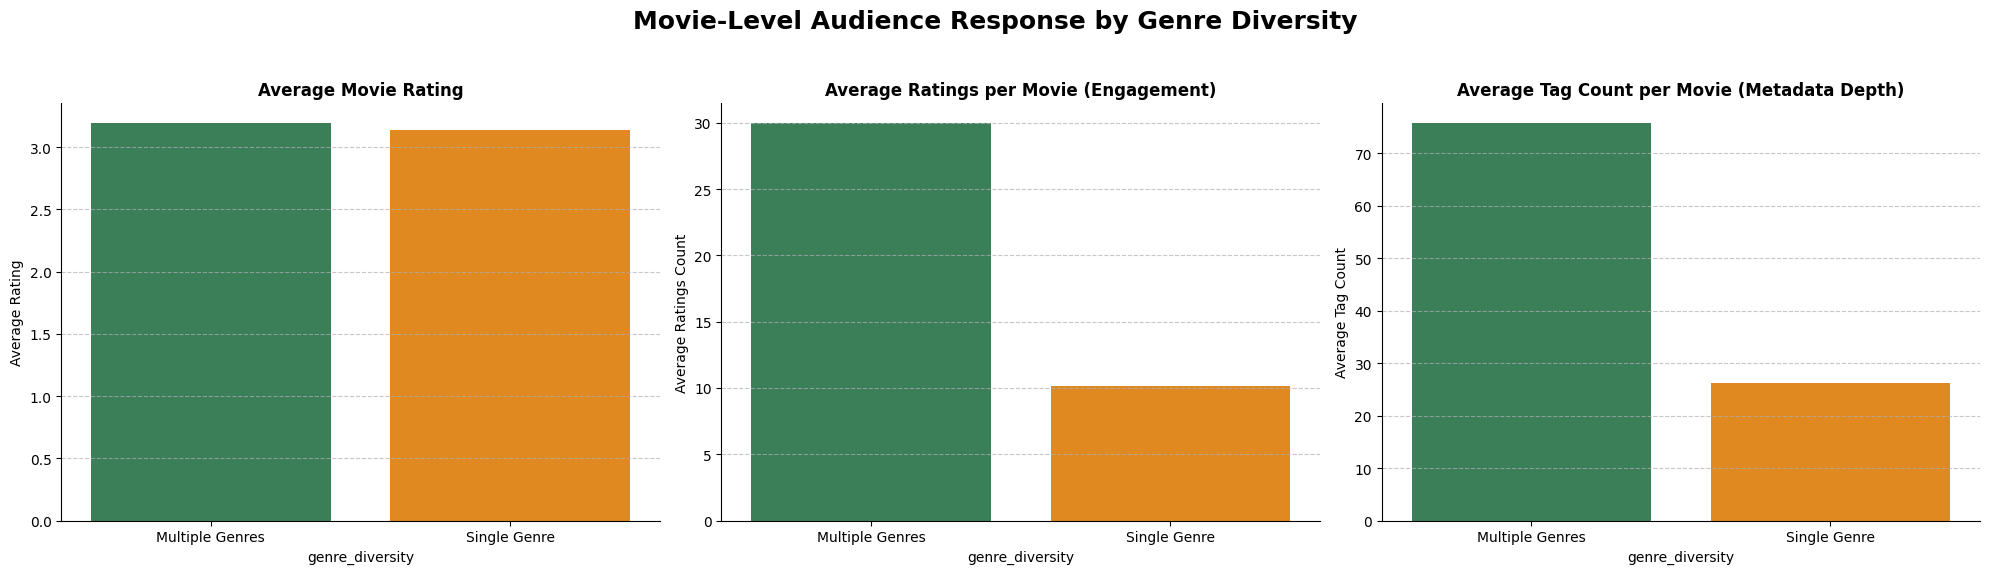

In [ ]:
# Load the prepared dataset explicitly to avoid NameError if session was restarted
movielens = pd.read_csv('movielens_analysis_ready.csv', parse_dates=['timestamp'])

# 1. Aggregate to the movie level first to avoid grain inflation (one row per movieId)
movie_level_genres = movielens[movielens['genres'] != '(no genres listed)'].groupby('movieId').agg({
    'genre_diversity': 'first',
    'rating': 'mean',          # Average rating for this movie
    'tag_count': 'first',       # Unique tag count for this movie
    'userId': 'count'          # Total engagement (ratings count) for this movie
}).reset_index()

# Fill NaN values in tag_count with 0
movie_level_genres['tag_count'] = movie_level_genres['tag_count'].fillna(0)

# 2. Group by genre diversity
genre_diversity_metrics = movie_level_genres.groupby('genre_diversity').agg(
    avg_rating=('rating', 'mean'),                     # Mean of movie-level average ratings
    avg_ratings_per_movie=('userId', 'mean'),          # Average rating volume per movie
    avg_tags_per_movie=('tag_count', 'mean'),          # Average tag count per movie
    total_movies=('movieId', 'count')                  # Total unique movies in category
).reset_index()

print("=" * 85)
print("Summary Table: Movie-Level Audience Response by Genre Diversity")
print("=" * 85)
print(genre_diversity_metrics.to_string())
print()

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle('Movie-Level Audience Response by Genre Diversity', fontsize=18, fontweight='bold')

custom_palette = {'Multiple Genres': 'seagreen', 'Single Genre': 'darkorange'}

sns.barplot(x='genre_diversity', y='avg_rating', data=genre_diversity_metrics, ax=axes[0], hue='genre_diversity', palette=custom_palette, legend=False)
axes[0].set_title('Average Movie Rating', fontweight='bold')
axes[0].set_ylabel('Average Rating')
axes[0].grid(axis='y', linestyle='--', alpha=0.7)
sns.despine(ax=axes[0])

sns.barplot(x='genre_diversity', y='avg_ratings_per_movie', data=genre_diversity_metrics, ax=axes[1], hue='genre_diversity', palette=custom_palette, legend=False)
axes[1].set_title('Average Ratings per Movie (Engagement)', fontweight='bold')
axes[1].set_ylabel('Average Ratings Count')
axes[1].grid(axis='y', linestyle='--', alpha=0.7)
sns.despine(ax=axes[1])

sns.barplot(x='genre_diversity', y='avg_tags_per_movie', data=genre_diversity_metrics, ax=axes[2], hue='genre_diversity', palette=custom_palette, legend=False)
axes[2].set_title('Average Tag Count per Movie (Metadata Depth)', fontweight='bold')
axes[2].set_ylabel('Average Tag Count')
axes[2].grid(axis='y', linestyle='--', alpha=0.7)
sns.despine(ax=axes[2])

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

## Question 5: Relationship between genre and audience rating shifted across overtime
Has the relationship between genre and audience rating shifted across overtime (by the year ratings were submitted), and if so, which genres are "rising" vs. "declining" in audience favor, with implications for content acquisition strategy?

In [ ]:
# 1. Load the prepared dataset
movielens = pd.read_csv('movielens_analysis_ready.csv', parse_dates=['timestamp'])

# 2. Extract the actual Rating Year from the transaction timestamp
movielens['rating_year'] = movielens['timestamp'].dt.year

# 3. Explode pipe-delimited genres to separate rows
genre_by_rating_time = movielens.assign(genre=movielens['genres'].str.split('|')).explode('genre')
genre_by_rating_time = genre_by_rating_time[genre_by_rating_time['genre'] != '(no genres listed)']

# 4. Group by Rating Year and Genre to calculate average ratings
genre_taste_trends = genre_by_rating_time.groupby(['rating_year', 'genre'])['rating'].agg(
    mean_rating='mean',
    num_ratings='count'
).reset_index()

# Filter out genres with under 100 ratings in a given rating year to reduce noise
genre_taste_trends = genre_taste_trends[genre_taste_trends['num_ratings'] >= 100]

# Pivot to inspect shifts in active taste over real-world rating years
taste_pivot = genre_taste_trends.pivot(index='genre', columns='rating_year', values='mean_rating')

print("=" * 95)
print("Pivot Table: Average Rating by Actual Rating Year (1997 - 2019)")
print("=" * 95)
print(taste_pivot.iloc[:, ::3].round(2).to_string()) # Display every 3rd year for brevity
print()

# Calculate true rating changes over active platform years (e.g. 2000 vs 2019)
taste_pivot['taste_change'] = taste_pivot[2019] - taste_pivot[2000]

print("=" * 75)
print("Genres with Rising Favor over Active Rating Time (2000 -> 2019)")
print("=" * 75)
print(taste_pivot[['taste_change']].sort_values('taste_change', ascending=False).dropna().head(5).to_string())
print()

print("=" * 75)
print("Genres with Declining Favor over Active Rating Time (2000 -> 2019)")
print("=" * 75)
print(taste_pivot[['taste_change']].sort_values('taste_change', ascending=True).dropna().head(5).to_string())

Pivot Table: Average Rating by Actual Rating Year (1997 - 2019)
rating_year  1996  1999  2002  2005  2008  2011  2014  2017
genre                                                      
Action       3.42  3.44  3.40  3.32  3.50  3.47  3.52  3.52
Adventure    3.47  3.52  3.55  3.43  3.53  3.50  3.58  3.56
Animation    3.68  3.66  3.59  3.57  3.59  3.58  3.52  3.53
Children     3.47  3.46  3.32  3.39  3.35  3.37  3.36  3.42
Comedy       3.39  3.54  3.38  3.35  3.44  3.42  3.56  3.45
Crime        3.59  3.82  3.62  3.56  3.73  3.72  3.75  3.82
Documentary   NaN   NaN   NaN  3.60   NaN   NaN   NaN   NaN
Drama        3.68  3.75  3.63  3.59  3.67  3.71  3.73  3.73
Fantasy      3.43  3.56  3.50  3.47  3.59  3.51  3.58  3.62
Film-Noir     NaN  4.19   NaN  4.00   NaN   NaN   NaN   NaN
Horror       3.53  3.26  3.24  3.20  3.39  3.36  3.45  3.44
IMAX         3.76   NaN   NaN  3.49  3.53   NaN   NaN  3.46
Musical      3.60  3.69  3.52  3.48  3.46  3.49   NaN  3.55
Mystery      3.72  3.73  3.70  3.56 

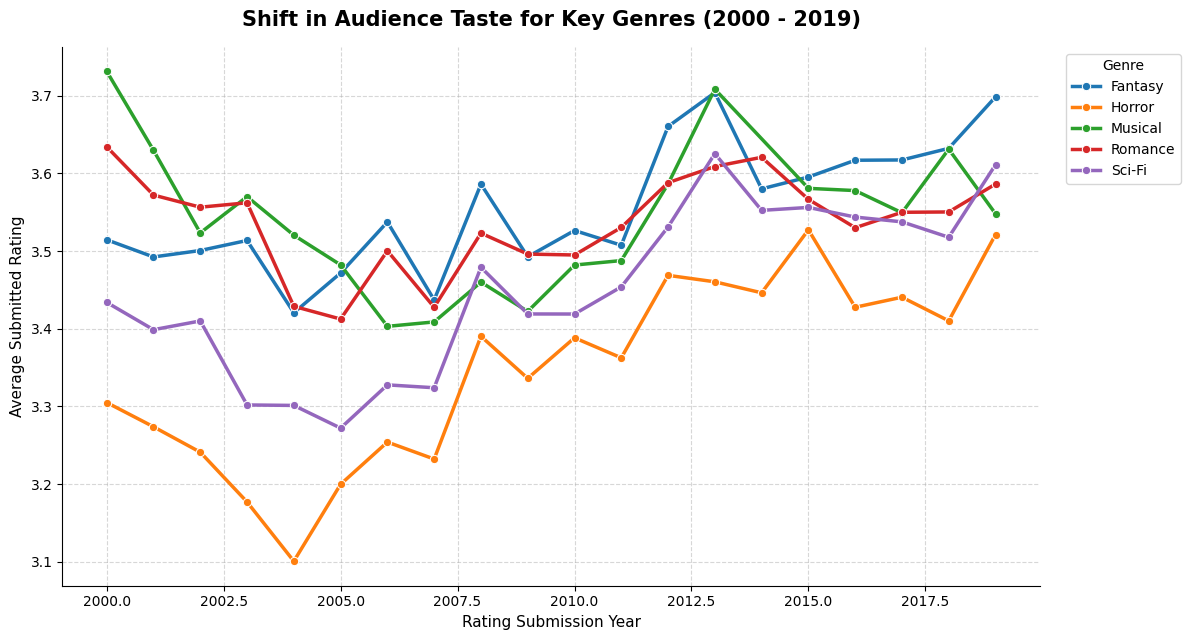

In [ ]:
# Filter taste trends dataset for key comparison genres
key_comparison = ['Horror', 'Sci-Fi', 'Fantasy', 'Musical', 'Romance']
filtered_trends = genre_taste_trends[(genre_taste_trends['genre'].isin(key_comparison)) & (genre_taste_trends['rating_year'] >= 2000)]

plt.figure(figsize=(12, 6.5))
sns.lineplot(data=filtered_trends, x='rating_year', y='mean_rating', hue='genre', marker='o', linewidth=2.5)
plt.title('Shift in Audience Taste for Key Genres (2000 - 2019)', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Rating Submission Year', fontsize=11)
plt.ylabel('Average Submitted Rating', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Genre', bbox_to_anchor=(1.02, 1), loc='upper left')
sns.despine()
plt.tight_layout()
plt.show()